In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load dataset
df = pd.read_csv('ai4i2020.csv')

print('Dataset loaded successfully.')
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
print('Preview of the dataset:')
df.head()

Dataset loaded successfully.
Rows: 10000, Columns: 14
Preview of the dataset:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Preview first rows
print('First 5 rows of the dataset:')
df.head()

First 5 rows of the dataset:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# Preview last rows
print('Last 5 rows of the dataset:')
df.tail()

Last 5 rows of the dataset:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [5]:
# Show dataset shape
print('Dataset shape:')
print(df.shape)

Dataset shape:
(10000, 14)


In [6]:
# List dataset columns
print('Column names in the dataset:')
print(df.columns.tolist())

Column names in the dataset:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [7]:
# Show column data types
print('Data types of each column:')
df.dtypes

Data types of each column:


UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [8]:
# Summarize numerical data
print('Summary statistics of the numerical columns:')
df.describe().T

Summary statistics of the numerical columns:


,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [9]:
# Check missing values
print('Missing values in each column:')
df.isnull().sum()

Missing values in each column:


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Histogram of numerical features:


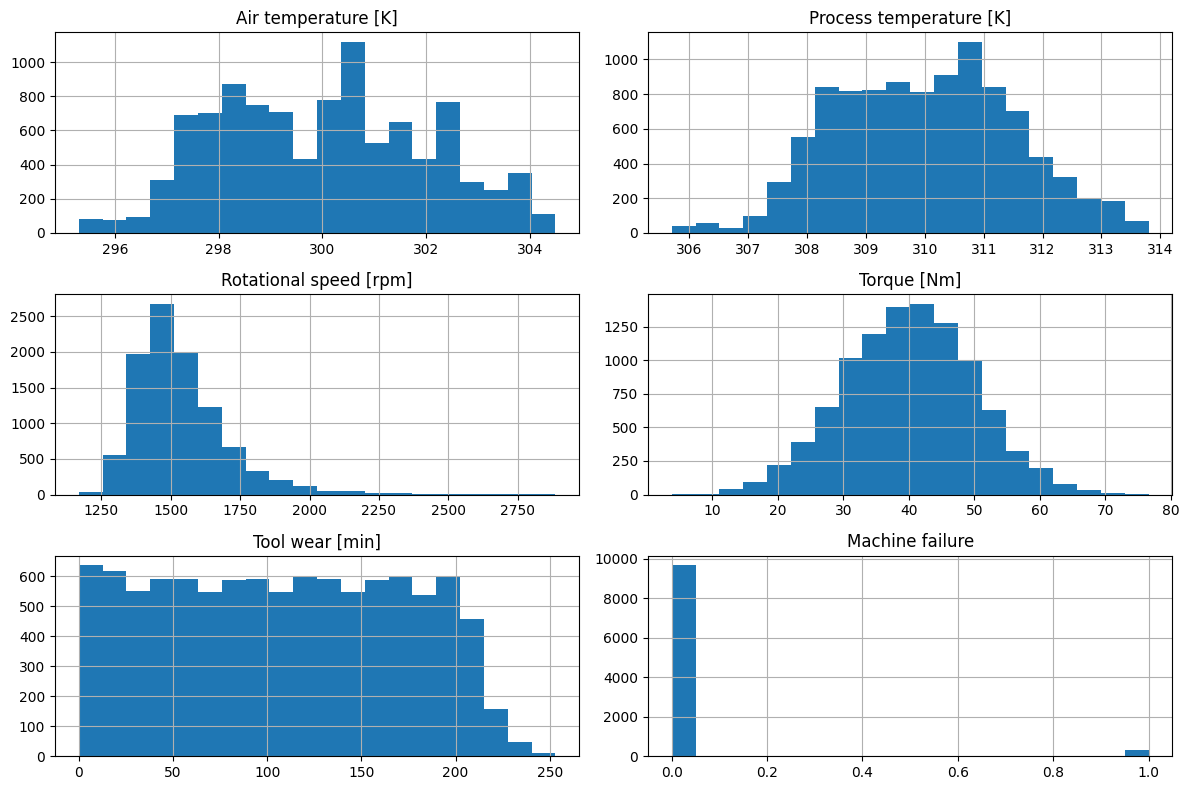

In [10]:
# Plot feature histograms
print('Histogram of numerical features:')
numerical_columns = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']
df[numerical_columns].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

Scatter plot: Process temperature vs Rotational speed


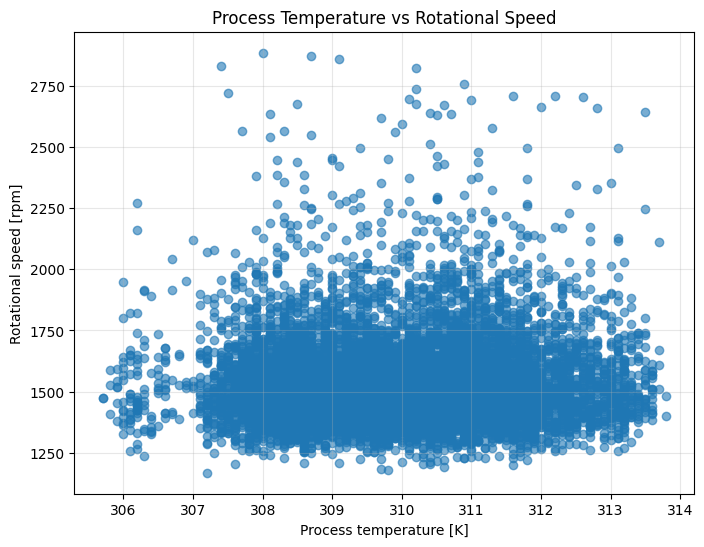

In [11]:
# Plot feature scatter
print('Scatter plot: Process temperature vs Rotational speed')
plt.figure(figsize=(8, 6))
plt.scatter(df['Process temperature [K]'], df['Rotational speed [rpm]'], alpha=0.6)
plt.title('Process Temperature vs Rotational Speed')
plt.xlabel('Process temperature [K]')
plt.ylabel('Rotational speed [rpm]')
plt.grid(True, alpha=0.3)
plt.show()

Box plot of numerical variables:


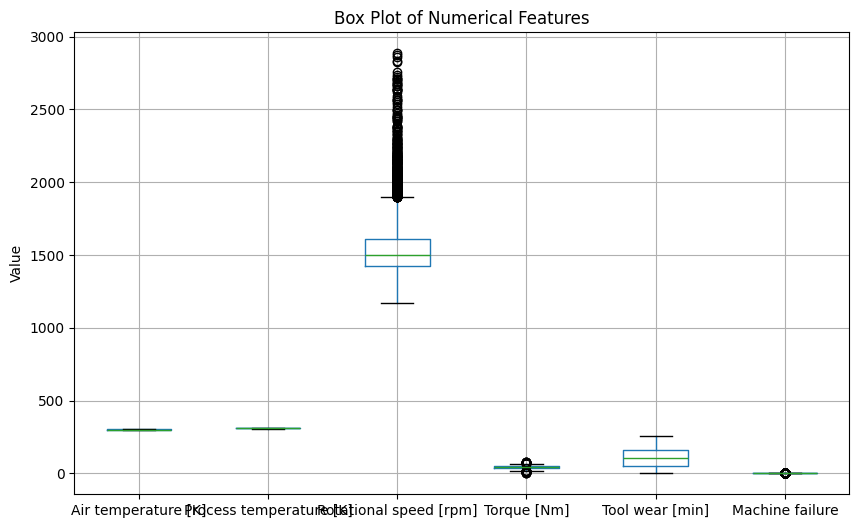

In [12]:
# Plot numerical box plots
print('Box plot of numerical variables:')
df[['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']].boxplot(figsize=(10, 6))
plt.title('Box Plot of Numerical Features')
plt.ylabel('Value')
plt.show()

Heatmap of feature correlations:


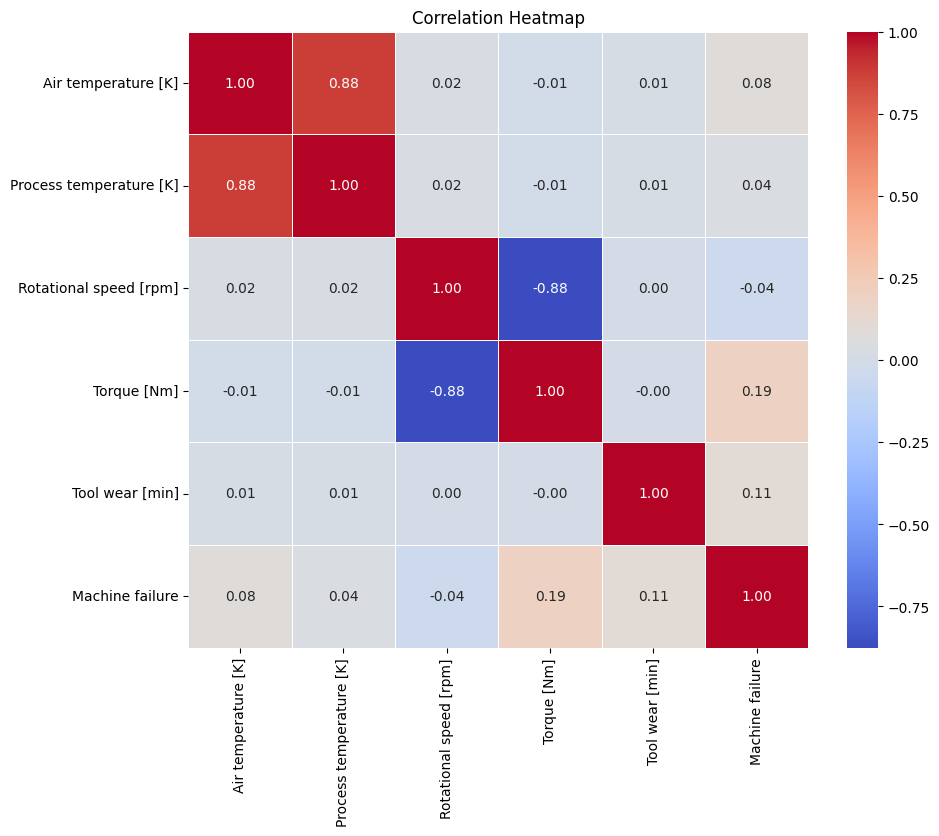

In [13]:
# Plot correlation heatmap
print('Heatmap of feature correlations:')
corr = df[['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

Bar plot: average machine failure by product type


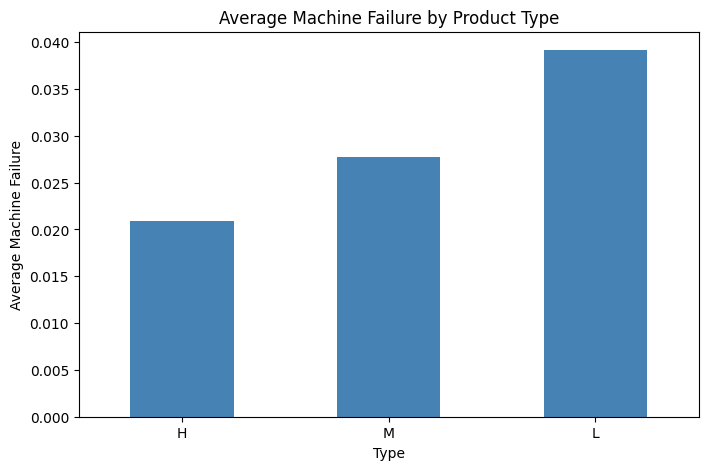

In [14]:
# Plot failure rate by type
print('Bar plot: average machine failure by product type')
failure_by_type = df.groupby('Type')['Machine failure'].mean().sort_values()
plt.figure(figsize=(8, 5))
failure_by_type.plot(kind='bar', color='steelblue')
plt.title('Average Machine Failure by Product Type')
plt.xlabel('Type')
plt.ylabel('Average Machine Failure')
plt.xticks(rotation=0)
plt.show()

In [15]:
# Set target variable
y = df['Machine failure']
print('Target variable prepared.')
print(y.head())

Target variable prepared.
0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64


In [16]:
# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=42, stratify=y)
print('Training and testing split completed.')
print(f'Training samples: {X_train.shape[0]}')
print(f'Testing samples: {X_test.shape[0]}')

Training and testing split completed.
Training samples: 8000
Testing samples: 2000


In [17]:
# Select model features
categorical_feature = ['Type']
numerical_feature = ['Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
print('Features prepared for preprocessing.')

Features prepared for preprocessing.


In [18]:
# Configure preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_feature),
    ('cat', OneHotEncoder(), categorical_feature)
])
print('Preprocessor created successfully.')

Preprocessor created successfully.


In [19]:
# Create linear SVM pipeline
linear_svm = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='linear'))
])
print('Linear SVM pipeline created.')

Linear SVM pipeline created.


In [20]:
# Train linear SVM model
linear_svm.fit(X_train, y_train)
print('Linear SVM model trained.')

Linear SVM model trained.


In [21]:
# Predict with linear SVM
y_pred_linear = linear_svm.predict(X_test)
print('Linear SVM predictions generated.')

Linear SVM predictions generated.


In [22]:
# Evaluate linear SVM
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear, zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear, zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear, zero_division=0)

print('Linear SVM Model Performance')
print('Accuracy:', accuracy_linear)
print('Precision:', precision_linear)
print('Recall:', recall_linear)
print('F1 Score:', f1_linear)

Linear SVM Model Performance
Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [23]:
# Show linear SVM classification report
print(classification_report(y_test, y_pred_linear, target_names=['No Failure', 'Failure'], zero_division=0))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



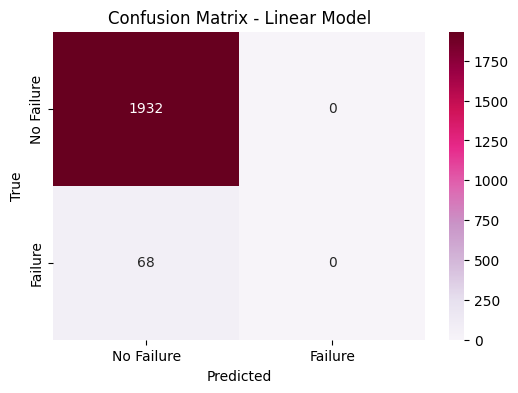

In [24]:
# Plot linear SVM confusion matrix
cm_linear = confusion_matrix(y_test, y_pred_linear)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_linear, annot=True, fmt='d', cmap='PuRd', xticklabels=['No Failure', 'Failure'], yticklabels=['No Failure', 'Failure'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - Linear Model')
plt.show()

In [25]:
# Create RBF SVM pipeline
rbf_svm = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf'))
])
print('RBF SVM pipeline created.')

RBF SVM pipeline created.


In [26]:
# Train RBF SVM model
rbf_svm.fit(X_train, y_train)
print('RBF SVM model trained.')

RBF SVM model trained.


In [27]:
# Predict with RBF SVM
y_pred_rbf = rbf_svm.predict(X_test)
print('RBF SVM predictions generated.')

RBF SVM predictions generated.


In [28]:
# Evaluate RBF SVM
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf, zero_division=0)

print('RBF SVM Model Performance')
print('Accuracy:', accuracy_rbf)
print('Precision:', precision_rbf)
print('Recall:', recall_rbf)
print('F1 Score:', f1_rbf)

RBF SVM Model Performance
Accuracy: 0.9715
Precision: 0.9230769230769231
Recall: 0.17647058823529413
F1 Score: 0.2962962962962963


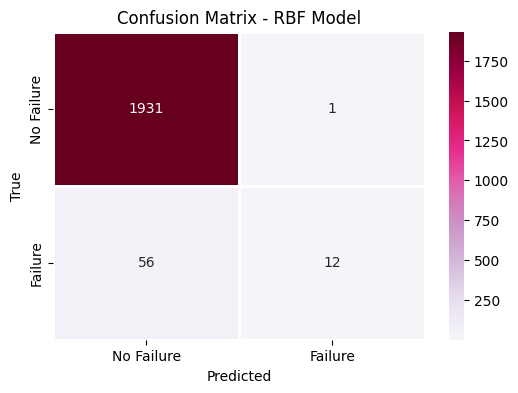

In [29]:
# Plot RBF SVM confusion matrix
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rbf, annot=True, fmt='d', cmap='PuRd', xticklabels=['No Failure', 'Failure'], yticklabels=['No Failure', 'Failure'], linewidths=1, linecolor='white')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - RBF Model')
plt.show()

In [30]:
# Compare model performance
comparison = pd.DataFrame({
    'kernel': ['Linear', 'RBF'],
    'accuracy': [accuracy_linear, accuracy_rbf],
    'precision': [precision_linear, precision_rbf],
    'recall': [recall_linear, recall_rbf],
    'f1_score': [f1_linear, f1_rbf]
})
print('Model comparison summary:')
comparison

Model comparison summary:


,kernel,accuracy,precision,recall,f1_score
0,Linear,0.9660,0.000000,0.000000,0.000000
1,RBF,0.9715,0.923077,0.176471,0.296296
